# Figure 4

DISCOVER identifies a subset of Fisher-significant gene pairs, with their corresponding endpoint-level mutation patterns.

- **A** (cell "Panel A"): Fisher's exact test q and DISCOVER q of every pair significant under either method, in the experiments that have a DISCOVER-significant pair, grouped by experiment.
- **B** to **E** (one cell each, drawn by `draw_oncoplot`): oncoplots, one column per endpoint and one row per gene of that experiment's pairs in panel A. B is 42C_Tenaillon, C GYD, D stALE and E MS56_ALE_2022.
- **Key** (last cell): the legend shared by all panels, saved on its own.

Inputs: `data/analysis/ecoli/all_experiments/pairwise_all_methods_gene.csv` and `data/qc/ecoli/qc_mutations.tsv`. The experiments whose mutation data are not public have no rows in `qc_mutations.tsv`. For them, the figure reads `gene_by_endpoint.tsv` and `distinct_mutations.tsv` in `data/qc/ecoli/nonpublic/`.

Outputs: `figures/Figure_4/Figure_4_A`, `Figure_4_B` to `Figure_4_E` and `Figure_4_key`, each as .svg and .png.

Environment B. Panel letters and the final layout are added in Adobe Illustrator.

## Imports and shared style

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False

# Visual grammar:
#   COLOR  = direction   red = co-occurrence,  blue = mutual exclusivity
#   FILL   = method      solid = DISCOVER,     hollow = Fisher's exact test
INK    = "#000000"
C_CO   = "#8B2635"
C_ME   = "#2F6E8F"
C_GREY = "#6E7A85"
C_LINK = "#c8cfd5"

mpl.rcParams["text.color"] = INK
mpl.rcParams["axes.labelcolor"] = INK
mpl.rcParams["xtick.color"] = INK
mpl.rcParams["ytick.color"] = INK

# Folders. The notebook runs from code/, so the folder above it holds data/, cache/ and figures/.
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"            # pipeline outputs (the results/ folder of ale-cooccurrence-nf)
FIG_DIR = ROOT / "figures/Figure_4"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"data folder not found: {DATA_DIR}")
if not (ROOT / "code/Figure_4.ipynb").is_file():
    raise FileNotFoundError(f"run this notebook from the code/ folder (working folder: {Path.cwd()})")
FIG_DIR.mkdir(parents=True, exist_ok=True)

ANA_DIR = DATA_DIR / "analysis/ecoli/all_experiments"
# What the figure uses of the experiments whose mutation data are not public. These files belong to
# this folder, so they are read from here also when DATA_DIR points to another run.
NONPUB_DIR = ROOT / "data/qc/ecoli/nonpublic"

SAVE, DPI = True, 300
Q_THR = 0.05

# Display names (kpsE, kpsD) for two E. coli B locus tags, following the mutation list of
# Tenaillon et al. 2012. The map changes the labels only: every lookup uses the locus tag.
RENAME = {"ECB_02815": "kpsE", "ECB_02816": "kpsD"}
disp = lambda g: RENAME.get(g, g)

# ---- ONE control for the text of the oncoplots (panels B to E) ---------------
FONTSIZE = 15          # gene labels, axis titles, annotations
# -----------------------------------------------------------------------------
for _k in ("font.size", "axes.labelsize", "axes.titlesize",
           "xtick.labelsize", "ytick.labelsize", "legend.fontsize"):
    mpl.rcParams[_k] = FONTSIZE

## Load, and build the panel A table

One row per significant pair in the experiments that contain a DISCOVER hit. "Significant"
means significant under either method, so the rows Fisher's exact test finds and DISCOVER
declines are included.

In [2]:
pairs = pd.read_csv(ANA_DIR / "pairwise_all_methods_gene.csv", low_memory=False)
flag = lambda c: pairs[c].map(lambda x: bool(x) if pd.notna(x) else False)

f_co, f_me = flag("fisher_sig_co"), flag("fisher_sig_mutex")
d_co, d_me = flag("discover_sig_co"), flag("discover_sig_mutex")
sig_any = f_co | f_me | d_co | d_me

DISC_EXPS = sorted(set(pairs.loc[d_co | d_me, "exp"]))          # experiments with a DISCOVER hit

def short(e):
    if e.startswith("42C_Tenaillon"): return "42 °C Tenaillon"
    if e.startswith("TOL_coumaric"):  return "TOL coumaric acid"
    return e

rows = []
for _, r in pairs[sig_any & pairs.exp.isin(DISC_EXPS)].iterrows():
    is_co = bool(r.fisher_sig_co is True or r.discover_sig_co is True)
    rows.append(dict(
        exp=short(r.exp), N=int(r.n_samples),
        pair=f"{disp(r.unit1)} \u2013 {disp(r.unit2)}",
        direction="co-occurrence" if is_co else "mutual exclusivity",
        fq=r.fisher_q_co_bh_local if is_co else r.fisher_q_mutex_bh_local,
        dq=r.discover_q_co_local   if is_co else r.discover_q_mutex_local,
        both=bool(r.discover_sig_co is True or r.discover_sig_mutex is True)))
panelA = pd.DataFrame(rows)

# largest experiment first, and within an experiment, most significant (under Fisher) at the top
order = panelA.groupby("exp").N.first().sort_values(ascending=False).index.tolist()
panelA["_e"] = panelA.exp.map({e: i for i, e in enumerate(order)})
panelA = panelA.sort_values(["_e", "fq"]).drop(columns="_e").reset_index(drop=True)

print(f"{len(panelA)} significant pairs across {panelA.exp.nunique()} experiments "
      f"({int(panelA.both.sum())} also significant under DISCOVER)\n")
print(panelA.assign(fq=lambda x: x.fq.map("{:.2e}".format),
                    dq=lambda x: x.dq.map(lambda v: "-" if pd.isna(v) else f"{v:.3f}"))
      .to_string(index=False))

12 significant pairs across 4 experiments (5 also significant under DISCOVER)

            exp   N        pair          direction       fq    dq  both
42 °C Tenaillon 111  rho – rpoB mutual exclusivity 1.51e-05 0.054 False
42 °C Tenaillon 111  ilvL – rho mutual exclusivity 1.24e-04 0.007  True
42 °C Tenaillon 111  mrdA – rho mutual exclusivity 3.32e-04 0.007  True
42 °C Tenaillon 111 rpoB – rpoC mutual exclusivity 9.34e-04 0.098 False
42 °C Tenaillon 111  iclR – rho      co-occurrence 1.21e-02 1.000 False
42 °C Tenaillon 111 kpsD – clsA mutual exclusivity 1.34e-02 0.095 False
42 °C Tenaillon 111 clsA – rpoB mutual exclusivity 3.76e-02 0.475 False
42 °C Tenaillon 111 kpsE – clsA mutual exclusivity 4.11e-02 0.178 False
            GYD  30  crr – cyaA mutual exclusivity 3.59e-03 0.019  True
          stALE  18 rpoB – rpoC mutual exclusivity 5.39e-05 0.005  True
          stALE  18 fliK – tnaA      co-occurrence 4.58e-02 0.530 False
  MS56_ALE_2022  16 rpoB – rpoD mutual exclusivity 1.05e-

## Panel A

Adjustable knobs are collected at the top of the cell. `A_XMAX` is worth watching: Fisher's
q-values can span several orders of magnitude, so some rows reach much further right than
others and the short dumbbells can become hard to read.

wrote figures/Figure_4/Figure_4_A.png


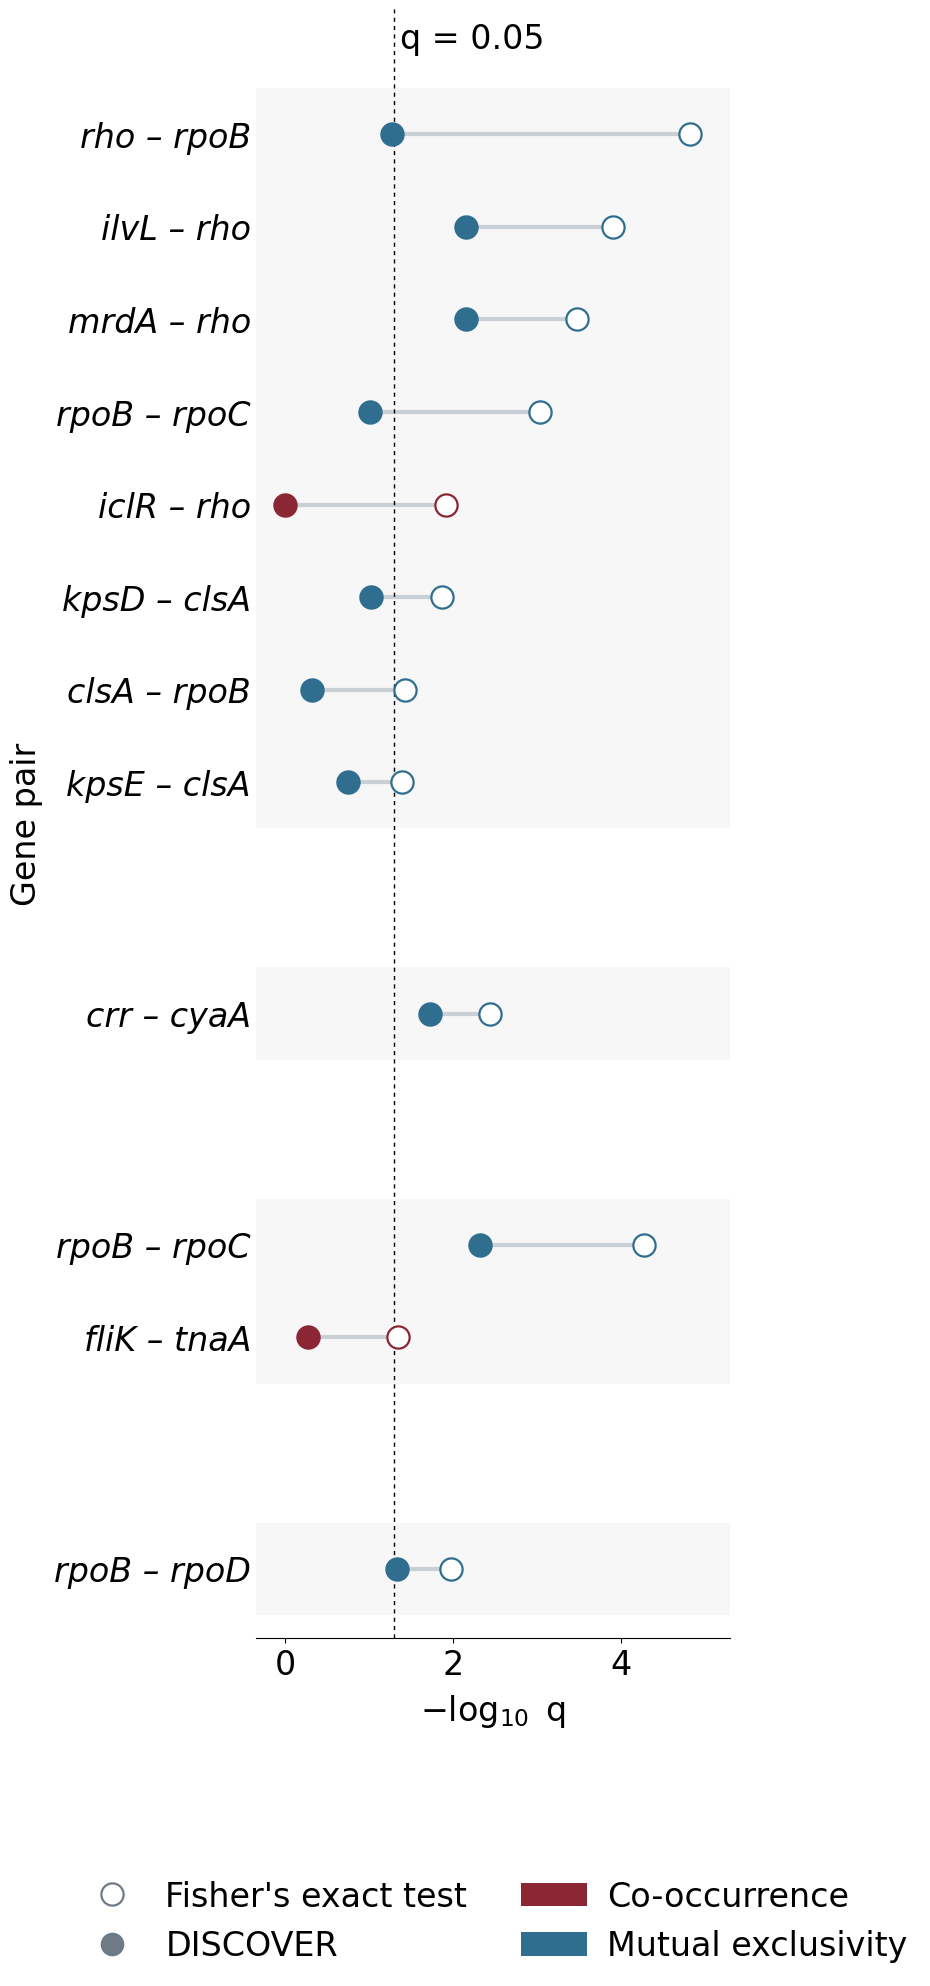

In [3]:
# ---- knobs -----------------------------------------------------------------
A_ROW_H       = 1    # HEIGHT OF ONE PAIR ROW, in inches: raise to make the rows taller
A_GROUP_GAP   = 1.5    # gap between experiment blocks, counted in row heights
                        # (so the gap is A_GROUP_GAP * A_ROW_H inches: lower it if you raise
                        #  A_ROW_H and want the blocks to stay the same distance apart)
A_XMAX        = None    # None = auto from the data
A_MS          = 16      # marker size, in points (diameter of the dumbbell ends).
                        # A_ROW_H is in INCHES, so one row is A_ROW_H * 72 points.
                        # Keep A_MS well under that or the markers touch across rows.
A_LW          = 3.0     # thickness of the line joining a pair's two q-values
A_BAND_ALPHA  = 0.055   # tint behind each experiment block
A_LEG_NCOL    = 2       # legend sits under the axes (2 = two rows of two)
A_FONTSIZE    = 24      # ALL text in this panel, independent of the notebook-wide
                        # FONTSIZE (which the oncoplots use). Set it to FONTSIZE to
                        # put panel A in sync with them.
# -----------------------------------------------------------------------------

lg = lambda v: -np.log10(np.clip(np.asarray(v, float), 1e-13, 1.0))
groups = [(e, panelA[panelA.exp == e]) for e in panelA.exp.drop_duplicates()]
n_slots = len(panelA) + A_GROUP_GAP * len(groups)

fig, ax = plt.subplots(figsize=(8.6, max(3.0, n_slots * A_ROW_H + 2)))
xmax = A_XMAX if A_XMAX else lg(panelA.fq.min()) * 1.10

y, ticks, labels = 0.0, [], []
for _e, g in groups[::-1]:                      # bottom-up, so the largest block ends on top
    y_bot = y - 0.5
    for _, r in g.iloc[::-1].iterrows():
        col = C_CO if r.direction == "co-occurrence" else C_ME
        xf = lg(r.fq)
        xd = lg(r.dq) if pd.notna(r.dq) else np.nan
        if np.isfinite(xd):
            ax.plot([xd, xf], [y, y], color=C_LINK, lw=A_LW, zorder=1, solid_capstyle="round")
            # FILL ENCODES THE METHOD, NOTHING ELSE: DISCOVER solid, Fisher open.
            # Significance is read off the q = 0.05 line, never off the fill.
            ax.plot(xd, y, "o", ms=A_MS, mfc=col, mec=col, mew=1.6, zorder=3)
        ax.plot(xf, y, "o", ms=A_MS, mfc="white", mec=col, mew=1.6, zorder=3)
        ticks.append(y); labels.append(r.pair)
        y += 1.0
    y_top = y - 0.5
    ax.add_patch(Rectangle((-0.35, y_bot), xmax + 0.35, y_top - y_bot, facecolor=C_GREY,
                           alpha=A_BAND_ALPHA, edgecolor="none", zorder=0))
    y += A_GROUP_GAP

ax.axvline(lg(Q_THR), color=INK, lw=1.0, ls=(0, (3, 3)), zorder=2)
ax.annotate("q = 0.05", (lg(Q_THR), y - A_GROUP_GAP - 0.15), textcoords="offset points",
            xytext=(4, 0), fontsize=A_FONTSIZE, color=INK, ha="left", va="bottom")

ax.set_yticks(ticks); ax.set_yticklabels(labels, fontsize=A_FONTSIZE, style="italic")
ax.set_ylim(-0.75, y - A_GROUP_GAP + 0.35)
ax.set_xlim(-0.35, xmax)
ax.set_xlabel("$-\\log_{10}$ q", fontsize=A_FONTSIZE, color=INK, labelpad=8)
ax.set_ylabel("Gene pair", fontsize=A_FONTSIZE, color=INK, labelpad=8)
ax.tick_params(axis="x", labelsize=A_FONTSIZE)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.grid(False)

h = [Line2D([], [], ls="", marker="o", ms=A_MS, mfc="white", mec=C_GREY, mew=1.6,
            label="Fisher's exact test"),
     Line2D([], [], ls="", marker="o", ms=A_MS, mfc=C_GREY, mec=C_GREY,
            label="DISCOVER"),
     Patch(facecolor=C_CO, label="Co-occurrence"),
     Patch(facecolor=C_ME, label="Mutual exclusivity")]
ax.legend(handles=h, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=A_LEG_NCOL,
          fontsize=A_FONTSIZE, frameon=False, handletextpad=.6, columnspacing=1.6)

fig.tight_layout()
if SAVE:
    fig.savefig(FIG_DIR / "Figure_4_A.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_4_A.png", dpi=DPI, bbox_inches="tight", facecolor="white")
    print("wrote", (FIG_DIR / "Figure_4_A.png").relative_to(ROOT))
plt.show()


## Panels B-E: the oncoplots, one experiment per cell

One cell per experiment, in the same order as panel A. Rows are the genes appearing in a pair
that the experiment reported as significant under either method. Panel B lists the same genes
by hand, in the order of the two adaptive routes. Columns
are every endpoint of the experiment, ordered by mutation pattern, so exclusivity and
co-occurrence read straight off the panel. Endpoints carrying none of the genes collect at the
right-hand end.

The shared helper sits in the next cell. Each panel cell after it sets its knobs and draws one
experiment.

In [4]:
# ---- shared by the four oncoplot cells below --------------------------------
ONC_FILL  = "#458B57"    # a gene mutated in that endpoint. DELIBERATELY NOT C_CO or C_ME:
                         # in panel A those two encode DIRECTION, so reusing either here
                         # would make one color mean two things inside one figure.
ONC_EMPTY = "#eef1f4"    # a gene not mutated in that endpoint
# -----------------------------------------------------------------------------

qc = pd.read_csv(DATA_DIR / "qc/ecoli/qc_mutations.tsv",
                 sep="\t", low_memory=False)
# The experiments whose mutation data are not public have no rows in qc. For them, NONPUB_DIR holds
# the genes mutated in each endpoint and the distinct-mutation count of each gene the panels draw.
nonpub_cells = pd.read_csv(NONPUB_DIR / "gene_by_endpoint.tsv", sep="\t")
nonpub_distinct = pd.read_csv(NONPUB_DIR / "distinct_mutations.tsv", sep="\t")
NONPUB_EXPS = set(nonpub_cells.exp)
if NONPUB_EXPS & set(qc.exp):
    raise ValueError(f"experiments both in qc_mutations.tsv and in {NONPUB_DIR}: "
                     f"{sorted(NONPUB_EXPS & set(qc.exp))}")
if nonpub_cells.isna().any().any() or nonpub_distinct.isna().any().any():
    raise ValueError(f"empty values in the files of {NONPUB_DIR}")
if not (set(zip(nonpub_distinct.exp, nonpub_distinct.Gene_name_normalized))
        <= set(zip(nonpub_cells.exp, nonpub_cells.Gene_name_normalized))):
    raise ValueError("distinct_mutations.tsv counts a gene that gene_by_endpoint.tsv does not list")
# the genes mutated in each endpoint of every experiment, the cells the oncoplots draw
_cols = ["exp", "sample_endpoint", "Gene_name_normalized"]
cells = pd.concat([qc[_cols], nonpub_cells[_cols]], ignore_index=True)

EXP_FULL = {short(e): e for e in DISC_EXPS}      # panel A's label -> the full experiment name


def onc_data(exp_full, genes=None):
    # Rows, columns and the mutated set for one experiment. genes=None takes the genes that
    # appear in a pair this experiment reported as significant under either method.
    auto = genes is None
    if auto:
        s = pairs[sig_any & (pairs.exp == exp_full)]
        genes = sorted(set(s.unit1) | set(s.unit2))
    sub = cells[cells.exp == exp_full]
    hit = {g: set(sub.loc[sub.Gene_name_normalized == g, "sample_endpoint"]) for g in genes}
    if auto:                       # automatic rows: most frequently mutated first
        genes = sorted(genes, key=lambda g: (-len(hit[g]), g))
    ep = sorted(sub.sample_endpoint.unique())
    ep = sorted(ep, key=lambda e: (tuple(0 if e in hit[g] else 1 for g in genes), e))
    return genes, ep, hit


def onc_size(genes, ep, row_h=0.30, col_w=0.075, pad_w=1.6, pad_h=0.85):
    return (max(3.0, len(ep) * col_w + pad_w), len(genes) * row_h + pad_h)


def draw_oncoplot(ax, genes, ep, hit, fill=None, empty=None, cell_gap=0.10,
                  fs_gene=None, fs_xlabel=None, xlabel=None, ylabel="Gene", divider=True,
                  row_note=False, note_fmt="{k}", note_w=1.0, fs_note=None, note_color=None):
    fill = ONC_FILL if fill is None else fill
    empty = ONC_EMPTY if empty is None else empty
    fs_gene = FONTSIZE if fs_gene is None else fs_gene
    fs_xlabel = FONTSIZE if fs_xlabel is None else fs_xlabel
    fs_note = FONTSIZE if fs_note is None else fs_note      # same size as the gene labels
    h = cell_gap / 2
    for gi, g in enumerate(genes):
        for ei, e in enumerate(ep):
            ax.add_patch(Rectangle((ei - 0.5 + h, gi - 0.5 + h), 1 - cell_gap, 1 - cell_gap,
                                   facecolor=fill if e in hit[g] else empty, edgecolor="none"))

    blank = [ei for ei, e in enumerate(ep) if not any(e in hit[g] for g in genes)]
    if divider and blank:
        ax.axvline(blank[0] - 0.5, color=INK, lw=1.0, ls=(0, (3, 3)), zorder=4)

    x_hi = len(ep) - 0.5
    if row_note:                       # distinct-mutation count, as in figure 5 panels B to D
        for gi, g in enumerate(genes):
            ax.annotate(note_fmt.format(k=n_distinct(g), n=len(hit[g])),
                        (x_hi + 0.35, gi), va="center", ha="left", fontsize=fs_note,
                        color=note_color or INK, annotation_clip=False)
        x_hi += 0.35 + note_w

    ax.set_xlim(-0.5, x_hi)
    ax.set_ylim(len(genes) - 0.5, -0.5)
    ax.set_yticks(range(len(genes)))
    ax.set_yticklabels([disp(g) for g in genes], fontsize=fs_gene, style="italic")
    ax.set_xticks([])
    ax.set_xlabel(f"{len(ep)} endpoints" if xlabel is None else xlabel,
                  fontsize=fs_xlabel, color=INK, labelpad=6)
    ax.set_ylabel(ylabel, fontsize=fs_xlabel, color=INK, labelpad=6)   # same size as the x title
    ax.tick_params(axis="y", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)


# tight_layout as if the y titles were absent, so a title never narrows its panel: every grid's cells
# keep the size the knobs give them, and bbox_inches="tight" widens the saved canvas on the
# left to take the title.
def tight_layout_keep_axes(fig):
    labels = [a.yaxis.label for a in fig.axes if a.yaxis.label.get_visible()]
    for lab in labels:
        lab.set_visible(False)
    fig.tight_layout()
    for lab in labels:
        lab.set_visible(True)


def onc_report(tag, genes, ep, hit):
    cov = len({e for g in genes for e in hit[g]})
    print(f"{tag}: {len(genes)} genes, {len(ep)} endpoints, {cov} carry at least one "
          f"({len(ep) - cov} carry none)")
    print("   " + "  ".join(f"{disp(g)} {len(hit[g])}/{n_distinct(g)}" for g in genes)
          + "   (endpoints/distinct mutations)")


# ---- distinct-mutation counts, the same quantity figure 5 reports ------------------------
# Number of distinct `Details` strings recorded for a gene within one experiment. A row marked 1
# is a gene mutated in several endpoints by the same mutation every time, which is what figure 5
# panel A counts as single-mutation recurrence, so the two figures cannot disagree.
# This counts distinct MUTATIONS, not distinct per-endpoint profiles: a gene can carry more than
# one mutation in the same endpoint, so a gene may show a count above 1 while every endpoint
# carries the identical set.
# For the experiments in NONPUB_DIR, the counts of the drawn genes come from distinct_mutations.tsv,
# counted the same way, and a drawn gene without a count stops the run.
K_DISTINCT = qc.groupby(["exp", "Gene_name_normalized"]).Details.apply(
    lambda x: x.astype(str).str.strip().nunique()).to_dict()
K_DISTINCT.update({(e, g): int(k) for e, g, k in zip(nonpub_distinct.exp,
                                                     nonpub_distinct.Gene_name_normalized,
                                                     nonpub_distinct.n_distinct_mutations)})
_CUR = {"exp": None}                       # set by each panel cell before it draws


def n_distinct(g):
    if _CUR["exp"] in NONPUB_EXPS and (_CUR["exp"], g) not in K_DISTINCT:
        raise KeyError(f"{_CUR['exp']}: no distinct-mutation count for {g} in distinct_mutations.tsv")
    return K_DISTINCT.get((_CUR["exp"], g), 0)


### Panel B: 42 °C Tenaillon

42 °C Tenaillon: 9 genes, 111 endpoints, 111 carry at least one (0 carry none)
   rpoB 73/47  rpoC 21/21  ilvL 29/8  mrdA 22/15  kpsD 12/6  kpsE 10/5  rho 43/26  clsA 52/42  iclR 35/33   (endpoints/distinct mutations)


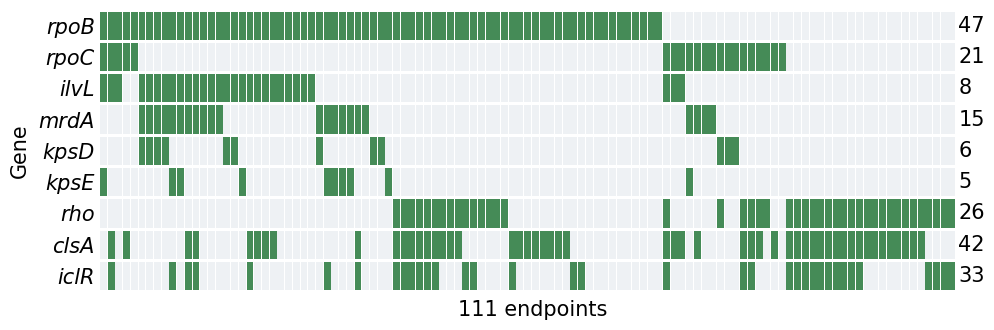

In [5]:
# ---- knobs -----------------------------------------------------------------
# Rows grouped by the two adaptive routes described by Tenaillon et al. 2012,
# used IN THE ORDER GIVEN. Raw locus tags here: RENAME turns them into kpsD / kpsE on the axis.
B_GENES   = ["rpoB", "rpoC",                            # the rpoBC core, kept adjacent
             "ilvL", "mrdA", "ECB_02816", "ECB_02815",
             "rho",                                     # the other route
             "clsA", "iclR"]
B_FIGSIZE = None     # None = sized from the data, else e.g. (9.0, 3.2)
B_CELLGAP = 0.10     # white space between cells, as a fraction of one cell
B_DIVIDER = False    # dashed rule before the endpoints carrying none of the genes
B_ROW_NOTE = True     # distinct-mutation count at the right of each row, as in figure 5
B_NOTE_FMT = "{k}"    # bare count ({k} = distinct mutations, {n} = endpoints)
B_NOTE_W   = 1.0      # space reserved for that note, in column widths
# -----------------------------------------------------------------------------

_CUR['exp'] = EXP_FULL['42 °C Tenaillon']
genes, ep, hit = onc_data(EXP_FULL['42 °C Tenaillon'], B_GENES)
fig, ax = plt.subplots(figsize=B_FIGSIZE or onc_size(genes, ep))
draw_oncoplot(ax, genes, ep, hit, cell_gap=B_CELLGAP, divider=B_DIVIDER,
              row_note=B_ROW_NOTE, note_fmt=B_NOTE_FMT, note_w=B_NOTE_W)
onc_report('42 °C Tenaillon', genes, ep, hit)

tight_layout_keep_axes(fig)
if SAVE:
    fig.savefig(FIG_DIR / "Figure_4_B.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_4_B.png", dpi=DPI, bbox_inches="tight",
                facecolor="white")
plt.show()

### Panel C: GYD

GYD: 2 genes, 30 endpoints, 24 carry at least one (6 carry none)
   cyaA 16/10  crr 8/8   (endpoints/distinct mutations)


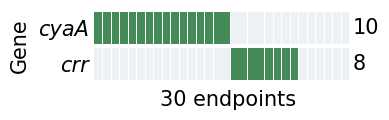

In [6]:
# ---- knobs -----------------------------------------------------------------
C_GENES   = None     # None = the genes in this experiment's significant pairs
C_FIGSIZE = None     # None = sized from the data, else e.g. (9.0, 3.2)
C_CELLGAP = 0.10     # white space between cells, as a fraction of one cell
C_DIVIDER = False    # dashed rule before the endpoints carrying none of the genes
C_ROW_NOTE = True     # distinct-mutation count at the right of each row, as in figure 5
C_NOTE_FMT = "{k}"    # bare count ({k} = distinct mutations, {n} = endpoints)
C_NOTE_W   = 1.0      # space reserved for that note, in column widths
# -----------------------------------------------------------------------------

_CUR['exp'] = EXP_FULL['GYD']
genes, ep, hit = onc_data(EXP_FULL['GYD'], C_GENES)
fig, ax = plt.subplots(figsize=C_FIGSIZE or onc_size(genes, ep))
draw_oncoplot(ax, genes, ep, hit, cell_gap=C_CELLGAP, divider=C_DIVIDER,
              row_note=C_ROW_NOTE, note_fmt=C_NOTE_FMT, note_w=C_NOTE_W)
onc_report('GYD', genes, ep, hit)

tight_layout_keep_axes(fig)
if SAVE:
    fig.savefig(FIG_DIR / "Figure_4_C.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_4_C.png", dpi=DPI, bbox_inches="tight",
                facecolor="white")
plt.show()

### Panel D: stALE

stALE: 4 genes, 18 endpoints, 18 carry at least one (0 carry none)
   rpoC 12/8  rpoB 6/6  fliK 2/1  tnaA 2/1   (endpoints/distinct mutations)


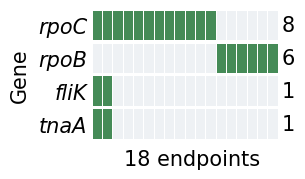

In [7]:
# ---- knobs -----------------------------------------------------------------
D_GENES   = None     # None = the genes in this experiment's significant pairs
D_FIGSIZE = None     # None = sized from the data, else e.g. (9.0, 3.2)
D_CELLGAP = 0.10     # white space between cells, as a fraction of one cell
D_DIVIDER = False    # dashed rule before the endpoints carrying none of the genes
D_ROW_NOTE = True     # distinct-mutation count at the right of each row, as in figure 5
D_NOTE_FMT = "{k}"    # bare count ({k} = distinct mutations, {n} = endpoints)
D_NOTE_W   = 1.0      # space reserved for that note, in column widths
# -----------------------------------------------------------------------------

_CUR['exp'] = EXP_FULL['stALE']
genes, ep, hit = onc_data(EXP_FULL['stALE'], D_GENES)
fig, ax = plt.subplots(figsize=D_FIGSIZE or onc_size(genes, ep))
draw_oncoplot(ax, genes, ep, hit, cell_gap=D_CELLGAP, divider=D_DIVIDER,
              row_note=D_ROW_NOTE, note_fmt=D_NOTE_FMT, note_w=D_NOTE_W)
onc_report('stALE', genes, ep, hit)

tight_layout_keep_axes(fig)
if SAVE:
    fig.savefig(FIG_DIR / "Figure_4_D.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_4_D.png", dpi=DPI, bbox_inches="tight",
                facecolor="white")
plt.show()

### Panel E: MS56_ALE_2022

MS56_ALE_2022: 2 genes, 16 endpoints, 14 carry at least one (2 carry none)
   rpoD 8/3  rpoB 6/2   (endpoints/distinct mutations)


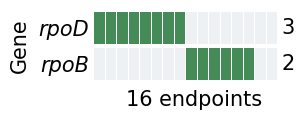

In [8]:
# ---- knobs -----------------------------------------------------------------
E_GENES   = None     # None = the genes in this experiment's significant pairs
E_FIGSIZE = None     # None = sized from the data, else e.g. (9.0, 3.2)
E_CELLGAP = 0.10     # white space between cells, as a fraction of one cell
E_DIVIDER = False    # dashed rule before the endpoints carrying none of the genes
E_ROW_NOTE = True     # distinct-mutation count at the right of each row, as in figure 5
E_NOTE_FMT = "{k}"    # bare count ({k} = distinct mutations, {n} = endpoints)
E_NOTE_W   = 1.0      # space reserved for that note, in column widths
# -----------------------------------------------------------------------------

_CUR['exp'] = EXP_FULL['MS56_ALE_2022']
genes, ep, hit = onc_data(EXP_FULL['MS56_ALE_2022'], E_GENES)
fig, ax = plt.subplots(figsize=E_FIGSIZE or onc_size(genes, ep))
draw_oncoplot(ax, genes, ep, hit, cell_gap=E_CELLGAP, divider=E_DIVIDER,
              row_note=E_ROW_NOTE, note_fmt=E_NOTE_FMT, note_w=E_NOTE_W)
onc_report('MS56_ALE_2022', genes, ep, hit)

tight_layout_keep_axes(fig)
if SAVE:
    fig.savefig(FIG_DIR / "Figure_4_E.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_4_E.png", dpi=DPI, bbox_inches="tight",
                facecolor="white")
plt.show()

## Key: the shared legend, drawn on its own

Saved as a separate asset so it can be placed anywhere in the assembled figure. It carries the
green swatch that panel A's own legend does not: the oncoplot fill is a third encoding and needs
declaring. Handle order is set so that with `L_NCOL = 2` the columns read

    Fisher's exact test          Co-occurrence
    DISCOVER                     Mutual exclusivity
    Gene mutated in an endpoint

In [9]:
# ---- knobs -----------------------------------------------------------------
L_FONTSIZE   = 24        # match A_FONTSIZE if the legend sits beside panel A
L_MS         = 22        # marker diameter in points (panel A uses A_MS)
L_NCOL       = 2         # 2 -> two columns: the methods and the oncoplot key on the left, the
                         # directions on the right
L_FIGSIZE    = (10.0, 3.0)
L_COLSPACE   = 2.0       # horizontal gap between columns
L_LABSPACE   = 1.0       # vertical gap between rows
L_HANDLEPAD  = 0.8       # gap between a swatch and its label
L_MUT_LABEL  = "Gene mutated in an endpoint"
# -----------------------------------------------------------------------------

# Column-major fill, so the order below is column 1 top-to-bottom, then column 2.
handles = [
    Line2D([], [], ls="", marker="o", ms=L_MS, mfc="white", mec=C_GREY, mew=1.6,
           label="Fisher's exact test"),
    Line2D([], [], ls="", marker="o", ms=L_MS, mfc=C_GREY, mec=C_GREY,
           label="DISCOVER"),
    Patch(facecolor=ONC_FILL, label=L_MUT_LABEL),
    Patch(facecolor=C_CO, label="Co-occurrence"),
    Patch(facecolor=C_ME, label="Mutual exclusivity"),
]

fig = plt.figure(figsize=L_FIGSIZE)
fig.legend(handles=handles, loc="center", ncol=L_NCOL, fontsize=L_FONTSIZE, frameon=False,
           handletextpad=L_HANDLEPAD, columnspacing=L_COLSPACE, labelspacing=L_LABSPACE)

if SAVE:
    fig.savefig(FIG_DIR / "Figure_4_key.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_4_key.png", dpi=DPI, bbox_inches="tight", facecolor="white")
    print("wrote", (FIG_DIR / "Figure_4_key.svg").relative_to(ROOT))
plt.show()

wrote figures/Figure_4/Figure_4_key.svg


<Figure size 1000x300 with 0 Axes>